# LE flux divergence — SCAR

Driver notebook for the latent-heat-flux-divergence analysis. Reads slow, EddyPro and regime/blowing-snow data, computes MO bulk fluxes at the surface and 26 m levels, then produces:

1. `fluxes_and_conditions` overview for **2025-04-23 – 2025-04-26**
2. LE divergence vs blowing-snow particle flux, coloured by the sign combination of LE$_{SFC}$ and the upper-level LE

Plotting logic lives in `src/plotting/func_plots_SCAR.py`.

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path

# Add project 'src' directory to sys.path when running from the notebooks/ folder.
repo_root = Path.cwd().parent
src_path = str(repo_root / 'src')
if src_path not in sys.path:
    sys.path.insert(0, src_path)

# Import modules from the installed package. If this fails, the editable install
# (`pip install -e .`) may be missing or the kernel needs a restart.
try:
    from ec.func_read_data import *
    from ec.sensor_info import *
    from mo.func_mo import *
    from spc.normalize import *
    from utils.utils import *
    from plotting.func_plots_SCAR import (
        plot_fluxes_and_conditions, plot_lhf_and_blsn, plot_le_divergence_signs,
        plot_shf_divergence_wind_stability,
        HEIGHT_COLORS, REGIME_COLORS,
    )
except Exception as e:
    print('Package import failed:', e)
    print('Make sure you ran `pip install -e .` (editable install) and restart the kernel, or that src/ exists at:', src_path)
else:
    %load_ext autoreload
    %autoreload 2
    %reload_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Read slow data

In [33]:
"""READ IN SLOW DATA"""

start = '2025-01-01'
end   = '2025-06-30'

folder_slow = '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/{sensor}'
slow_sfc    = read_data(folder_slow.format(sensor='SFC'),    'slow', 'SFC',    start, end, plot_data=False)
slow_bottom = read_data(folder_slow.format(sensor='BOTTOM'), 'slow', 'BOTTOM', start, end, plot_data=False)
slow_lower  = read_data(folder_slow.format(sensor='LOWER'),  'slow', 'LOWER',  start, end, plot_data=False)
slow_upper  = read_data(folder_slow.format(sensor='UPPER'),  'slow', 'UPPER',  start, end, plot_data=False)

ems   = 0.99
sigma = 5.67e-8
slow_sfc['Tskin_comp'] = ((slow_sfc['LWup1'] - (1 - ems) * slow_sfc['LWdown1']) / (ems * sigma))**0.25

# --- 2024 season ---
# The 2024 season used the single CSAT3 tower; under converted/ only SFC slow data
# exists, in date-prefixed folders (e.g. 20240118_SFC) that read_data matches via
# `sensor in root`, so pass the parent converted/ directory (not converted/SFC).
# There are no separate LOWER/UPPER/BOTTOM slow loggers for 2024.
start = '2024-01-01'
end   = '2024-12-30'

folder_slow_2024 = '/home/engbers/Documents/PhD/EC_data_convert/converted'
slow_sfc_2024 = read_data(folder_slow_2024, 'slow', 'SFC', start, end, plot_data=False)


Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202502
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202503
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202504
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202505
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202506
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202507
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202508
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202509
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202510
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_

## Read EddyPro fluxes

In [107]:
"""READ IN EDDYPRO DATA"""
folder = '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/'

fluxes_sfc    = read_eddypro_data(folder, 'SFC',   qc=False, qc_level=1, filename_filter='v3_5min')
fluxes_sfc_qc = read_eddypro_data(folder, 'SFC',   qc=True,  qc_level=1, filename_filter='v3_5min')
fluxes_low    = read_eddypro_data(folder, 'LOWER', qc=False, qc_level=1, filename_filter='v3_5min')
fluxes_up     = read_eddypro_data(folder, 'UPPER', qc=False, qc_level=1, filename_filter='v3_5min')

# --- 2024 season (single CSAT3 tower: SFC_DR, CSAT_16m_DR, CSAT_26m_DR) ---
folder_2024 = '/home/engbers/Documents/PhD/EC_data_convert/'

fluxes_sfc_2024    = read_eddypro_data(folder_2024, 'SFC_DR',      qc=False, qc_level=1)
fluxes_sfc_qc_2024 = read_eddypro_data(folder_2024, 'SFC_DR',      qc=True,  qc_level=1)
fluxes_low_2024    = read_eddypro_data(folder_2024, 'CSAT_16m_DR', qc=False, qc_level=1)
fluxes_up_2024     = read_eddypro_data(folder_2024, 'CSAT_26m_DR', qc=False, qc_level=1)


Files found: ['/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202504/eddypro_2025_v3_5min_biomet_full_output_2026-10-05T231533_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202509/eddypro_2025_v3_5min_biomet_full_output_2026-10-06T000843_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202505/eddypro_2025_v3_5min_biomet_full_output_2026-10-06T021642_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202507/eddypro_2025_v3_5min_biomet_full_output_2026-10-06T031121_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202506/eddypro_2025_v3_5min_biomet_full_output_2026-10-06T024344_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202508/eddypro_2025_v3_5min_biomet_full_output_2026-10-05T234116_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert

/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  
/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  
/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,1

Files found: ['/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202504/eddypro_2025_v3_5min_biomet_qc_details_2026-10-05T224522_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202509/eddypro_2025_v3_5min_biomet_qc_details_2026-10-05T234338_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202505/eddypro_2025_v3_5min_biomet_qc_details_2026-10-06T015114_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202507/eddypro_2025_v3_5min_biomet_qc_details_2026-10-06T024606_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202506/eddypro_2025_v3_5min_biomet_qc_details_2026-10-06T021908_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202508/eddypro_2025_v3_5min_biomet_qc_details_2026-10-05T231441_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/

/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  
/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  
/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,1

Files found: ['/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/UPPER/Eddypro_output/202504/eddypro_2025_v3_5min_biomet_full_output_2026-10-05T224354_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/UPPER/Eddypro_output/202505/eddypro_2025_v3_5min_biomet_full_output_2026-10-06T041834_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/UPPER/Eddypro_output/202506/eddypro_2025_v3_5min_biomet_full_output_2026-10-06T043905_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/UPPER/Eddypro_output/202503/eddypro_2025_v3_5min_biomet_full_output_2026-10-05T220705_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/UPPER/Eddypro_output/202502/eddypro_2025_v3_5min_biomet_full_output_2026-10-05T213240_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/UPPER/Eddypro_output/202512/eddypro_2025_v3_5min_biomet_full_output_2026-10-06T044513_adv.csv']


/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  
/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  
/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,1

Files found: ['/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202405/eddypro_May2024_full_output_2025-05-22T145422_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202408/eddypro_Aug2024_full_output_2025-05-23T090214_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202412/eddypro_Dec2024_full_output_2025-05-23T123929_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202407/eddypro_Jul2024_full_output_2025-05-22T164622_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202401/eddypro_SFC_Jan2024_full_output_2025-05-21T184431_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202404/eddypro_Apr2024_full_output_2025-05-22T135551_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202409/eddypro_Sep2024_full_output_2025-05-23T102118_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/20241

/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  
/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  
/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,1

Files found: ['/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202405/eddypro_May2024_qc_details_2025-05-22T145422_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202408/eddypro_Aug2024_qc_details_2025-05-23T090214_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202412/eddypro_Dec2024_qc_details_2025-05-23T123929_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202407/eddypro_Jul2024_qc_details_2025-05-22T164622_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202401/eddypro_SFC_Jan2024_qc_details_2025-05-21T184431_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202404/eddypro_Apr2024_qc_details_2025-05-22T135551_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202409/eddypro_Sep2024_qc_details_2025-05-23T102118_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/SFC_DR/Eddypro_output/202411/eddyp

In [108]:
"""READ IN EDDYPRO DATA"""
folder = '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/'

fluxes_low_nobiom    = read_eddypro_data(folder, 'SFC',   qc=False, qc_level=1, filename_filter='v2')


Files found: ['/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202504/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T085419_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202509/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T090524_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202505/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T092150_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202507/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T080930_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202506/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T094159_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202508/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T083611_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert

/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  
/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  
/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:9: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,1

(-400.0, 80.0)

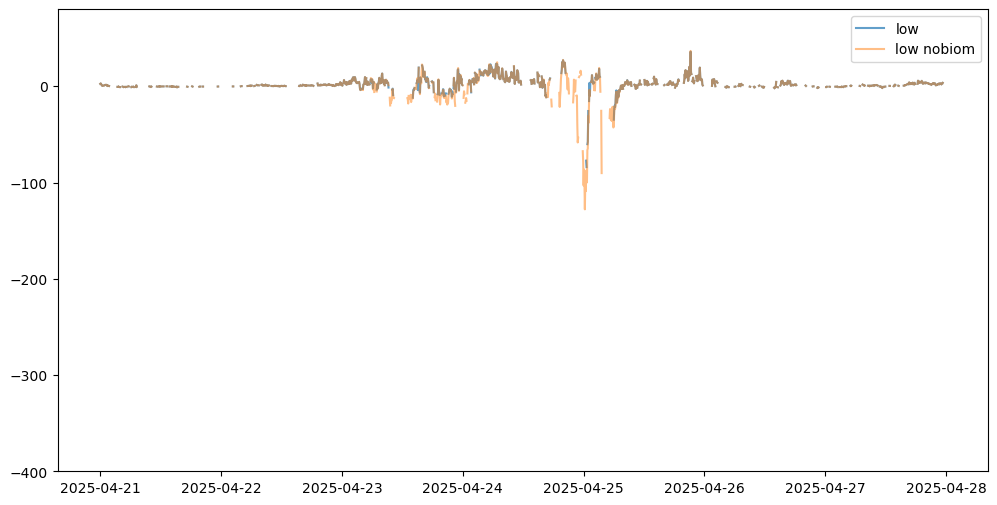

In [110]:
start = '2025-04-21'
end   = '2025-04-27'
plt.figure(figsize=(12, 6))
plt.plot(resample_with_threshold(fluxes_sfc['LE'], '5min', interpolate=False, max_gap='5min')[start:end], label='low', alpha=0.7)
plt.plot(resample_with_threshold(fluxes_low_nobiom['LE'], '5min', interpolate=False, max_gap='5min')[start:end], label='low nobiom', alpha=0.5)
plt.legend()
plt.ylim(-400, 80)

## Read regime clusters and blowing-snow detection

In [60]:
cluster = pd.read_csv('/home/engbers/Documents/PhD/Data/regimes/periods_by_regime_2025_k3_6h.csv',
                      index_col=0, parse_dates=True, header=0)

blsn_alg = pd.read_csv('/home/engbers/Documents/PhD/Data/regimes/blsn_2025_v1505_jump_25.csv',
                       index_col=0, parse_dates=True, header=0, na_values='99999999.9')
blsn_alg.index = pd.to_datetime(blsn_alg.index, errors='coerce')

## MO setup: sensor heights, snow-depth correction, roughness length

In [61]:
"""SETUP: sensor heights, snow depth correction, roughness length"""

year = 2025  # season 2024-2025 (change to 2026 for 2025-2026 season)

# Sensor heights for each datalogger (from sensor_info.py)
_, _, heights_sfc = get_sensor_info('SFC',    year=year)
_, _, heights_bot = get_sensor_info('BOTTOM', year=year)
_, _, heights_low = get_sensor_info('LOWER',  year=year)
_, _, heights_up  = get_sensor_info('UPPER',  year=year)

# Snow depth correction: z_eff(t) = z_ref - (HS_Cor(t) - HS_Cor_ref)
ref_dates = {2025: ('2025-02-11', '2025-02-12'), 2026: ('2026-01-13', '2026-01-14')}
SD_ref = slow_sfc['HS_Cor'].loc[ref_dates[year][0]:ref_dates[year][1]].mean()
dSD    = slow_sfc['HS_Cor'] - SD_ref  # [m], time series of snow depth change
print(f'Reference snow depth ({ref_dates[year][0]}): {SD_ref:.3f} m')

# Roughness length from SFC EC fluxes (neutral conditions only)
z0, z0rolling = compute_roughness_length(fluxes_sfc, fluxes_sfc_qc, heights_sfc['sonic'])

Using 2025 calibration coefficients
{'A': 4820.04, 'B': 3792900.0, 'C': -115477000.0, 'H2O_Zero': 0.7087, 'H20_Span': 0.9885}
None
{'A': 4764.8, 'B': 3848690.0, 'C': -127838000.0, 'H2O_Zero': 0.7311, 'H20_Span': 0.9883}
{'A': 5502.41, 'B': 4002660.0, 'C': -144890000.0, 'H2O_Zero': 0.8079, 'H20_Span': 1.0}
Reference snow depth (2025-02-11): 1.607 m


In [62]:
"""HELPER FUNCTION: iterative MO bulk flux calculation"""

def run_MO(ws, T_air_C, RH, T_surf_K, pressure_Pa, z_ws, z_TA, z0_series,
           start, end, resample_time='10min', min_pct=80):
    """Iterative Monin-Obukhov bulk flux calculation between the snow surface and a sensor level."""
    def _rs(x):
        if hasattr(x, 'index'):
            return resample_with_threshold(x, resample_time, min_valid_percent=min_pct)
        return x  # scalar passthrough

    dat = pd.concat([
        _rs(pressure_Pa).rename('pressure'),
        _rs(T_air_C).rename('TA'),
        _rs(z0_series).rename('z0'),
        _rs(ws).rename('ws'),
        (_rs(T_surf_K) - 273.15).rename('T_surf'),
        _rs(RH).rename('RH'),
    ], axis=1)[start:end]

    dat['z_ws']    = _rs(z_ws)[start:end]  if hasattr(z_ws, 'index') else z_ws
    dat['z_TA_RH'] = _rs(z_TA)[start:end]  if hasattr(z_TA, 'index') else z_TA

    dat['qv']           = RH_to_specific_humidity(dat['RH'], dat['TA'], dat['pressure'])
    dat['qv_surf']      = calc_qv_surface(dat['T_surf'], dat['pressure'])['qv_surf']
    dat['rho_air_surf'] = calc_qv_surface(dat['T_surf'], dat['pressure'])['rho_air_surf']
    dat['Ls']           = Lsubl(temp=dat['T_surf'].values)

    result = pd.DataFrame({
        'time': dat.index,
        'u_star': np.nan, 'Tw_flux': np.nan, 'qw_flux': np.nan,
        'zeta': np.nan, 'psi_m': np.nan, 'psi_s': np.nan, 'converged': np.nan
    })

    for i in range(len(dat)):
        d = dat.iloc[i]
        if d.isna().any() or d['z_ws'] <= 0 or d['z_TA_RH'] <= 0:
            continue
        fr = calc_fluxes_iter(
            z_ref_vw=d['z_ws'], z_ref_scalar=d['z_TA_RH'], rough_len_m=d['z0'],
            vw_ref=d['ws'], T_ref=d['TA'] + 273.15, qv_ref=d['qv'],
            T_surf=d['T_surf'] + 273.15, qv_surf=d['qv_surf']
        )
        for col, val in fr.items():
            if col in result.columns:
                result.at[i, col] = val

    result['LE'] = dat['Ls'].values * dat['rho_air_surf'].values * result['qw_flux']
    result['H']  = 1004 * dat['rho_air_surf'].values * result['Tw_flux']
    result.set_index('time', inplace=True)
    print(f'  Valid rows: {result.dropna(how="all").shape[0]} / {len(result)}')
    return result

Only the surface (~2 m) and upper (~26 m) MO fluxes are needed for the `fluxes_and_conditions` figure.

In [40]:
"""MO FLUXES — SFC (~2 m)"""

start_mo = '2025-01-01'
end_mo   = '2025-12-31'

# Snow-depth-corrected heights (time series)
z_ws_sfc = heights_sfc['WIND2'] - dSD   # lower Young wind monitor
z_TA_sfc = heights_sfc['TH']    - dSD

print('SFC MO:')
result_sfc = run_MO(
    ws=slow_sfc['WS2_Avg'],
    T_air_C=slow_sfc['TA'],
    RH=slow_sfc['RH'],
    T_surf_K=slow_sfc['Tskin_comp'],
    pressure_Pa=fluxes_sfc['air_pressure'],
    z_ws=z_ws_sfc,
    z_TA=z_TA_sfc,
    z0_series=z0rolling,
    start=start_mo, end=end_mo
)

SFC MO:


/home/engbers/Documents/Github/DataProcessingScripts/src/mo/func_mo.py:315: RuntimeWarning: divide by zero encountered in scalar divide
  zeta_new = -z_ref_scalar * kappa * (g / T_surf) * Tw_flux / u_star**3


  Valid rows: 20316 / 47020


In [41]:
"""MO FLUXES — UPPER (~26 m)"""

z_ws_up = heights_up['WIND'] - dSD
z_TA_up = heights_up['TH']   - dSD

print('UPPER 26m MO:')
result_up = run_MO(
    ws=slow_upper['WS_26m_Avg'],
    T_air_C=slow_upper['Temp_26m_Avg'],
    RH=slow_upper['RH_26m_Avg'],
    T_surf_K=slow_sfc['Tskin_comp'],
    pressure_Pa=slow_upper['AP_26m_Avg'] * 1000,   # kPa -> Pa
    z_ws=z_ws_up,
    z_TA=z_TA_up,
    z0_series=z0rolling,
    start=start_mo, end=end_mo
)

UPPER 26m MO:


/home/engbers/Documents/Github/DataProcessingScripts/src/mo/func_mo.py:315: RuntimeWarning: divide by zero encountered in scalar divide
  zeta_new = -z_ref_scalar * kappa * (g / T_surf) * Tw_flux / u_star**3


  Valid rows: 19738 / 47020


## Save MO fluxes (SFC + UPPER) to CSV, same format as `MO_fluxes_2024.csv`


In [42]:
"""SAVE MO FLUXES TO CSV — same layout as MO_fluxes_2024.csv"""
# MO_fluxes_2024.csv (repo root) is a plain `result.to_csv()` of run_MO output:
# index 'time' at 10 min, columns u_star, Tw_flux, qw_flux, zeta, psi_m, psi_s,
# converged, LE, H, with all-NaN rows kept. Do the same for the 2025 SFC and
# UPPER results so Fluxes.ipynb can read them back the same way:
#   pd.read_csv('../MO_fluxes_2025_SFC.csv', parse_dates=['time'], index_col=['time'])

out_dir = Path.cwd().parent   # repo root, next to MO_fluxes_2024.csv

for name, res in [('MO_fluxes_2025_SFC.csv', result_sfc),
                  ('MO_fluxes_2025_UP.csv',  result_up)]:
    path = out_dir / name
    res.to_csv(path)
    print(f'{name}: {len(res)} rows, {res.dropna(how="all").shape[0]} valid, '
          f'{res.index.min()} -> {res.index.max()}')


MO_fluxes_2025_SFC.csv: 47020 rows, 20316 valid, 2025-02-08 11:20:00 -> 2025-12-31 23:50:00
MO_fluxes_2025_UP.csv: 47020 rows, 19738 valid, 2025-02-08 11:20:00 -> 2025-12-31 23:50:00


## Plot 1 — fluxes and conditions (2025-04-23 – 2025-04-26)

In [103]:
import importlib, plotting.func_plots_SCAR as fps
importlib.reload(fps)
from plotting.func_plots_SCAR import plot_fluxes_and_conditions


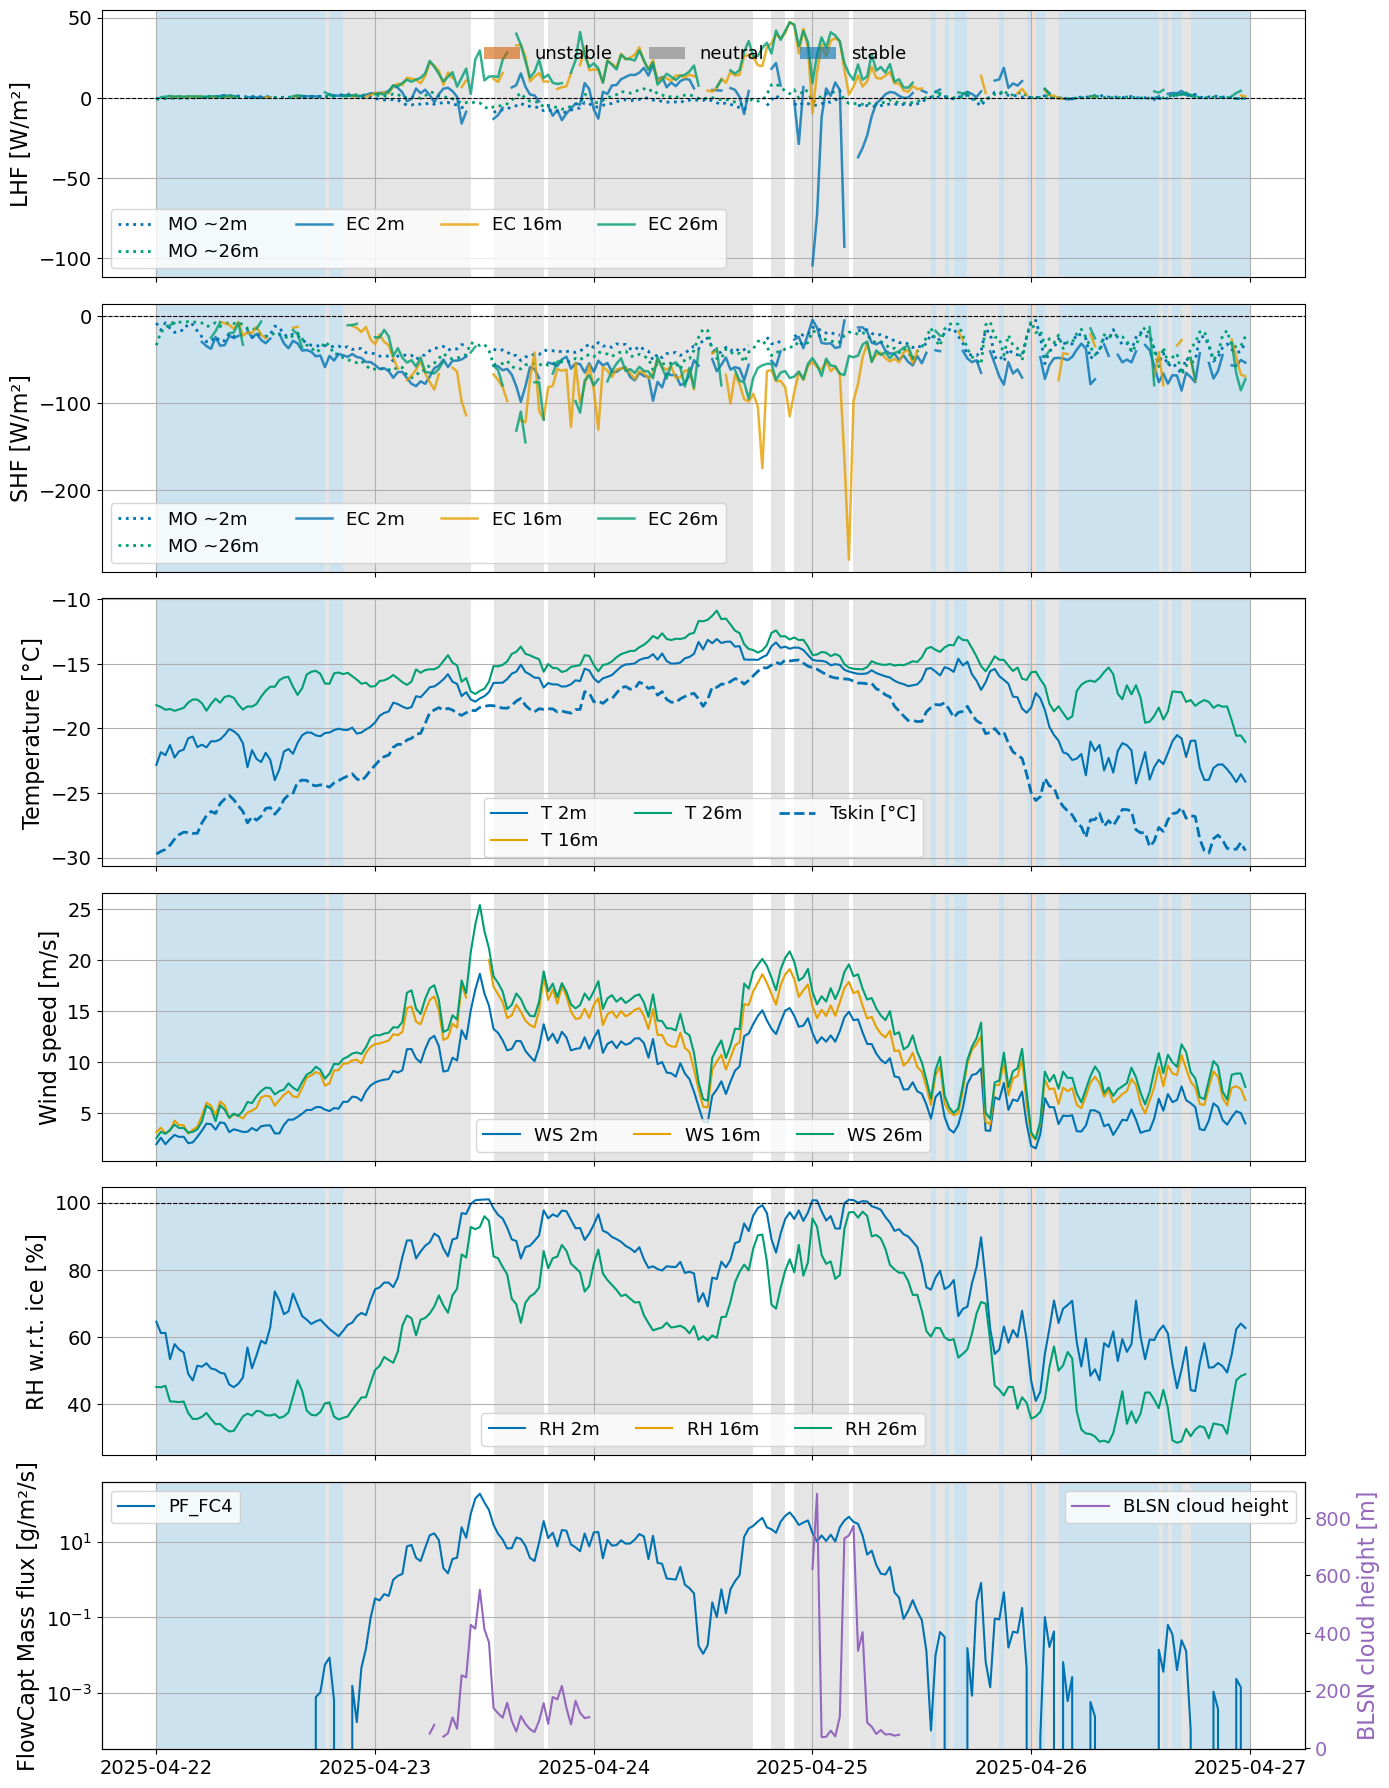

In [106]:
fig, axes = plot_fluxes_and_conditions(
    plot_start='2025-04-22', plot_end='2025-04-26',
    result_sfc=result_sfc, result_up=result_up,
    fluxes_sfc=fluxes_sfc, fluxes_low=fluxes_low, fluxes_up=fluxes_up,
    slow_sfc=slow_sfc, slow_lower=slow_lower, slow_upper=slow_upper,
    cluster=cluster, blsn_alg=blsn_alg,
    shade_by='stability',   # 'regime' for the cluster regimes, None for no shading
)
plt.savefig('/home/engbers/Documents/PhD/plot_results/paper1_div/WS_event_timeseries.png', dpi=400, bbox_inches='tight')

plt.show()

In [45]:
fluxes_low['H']['2025-04-25 03:30':'2025-04-25 04:40'].isna().all()


False

## Plot 1b — LHF and FlowCapt mass flux only

Same figure as Plot 1, reduced to the LHF and blowing-snow mass flux panels.

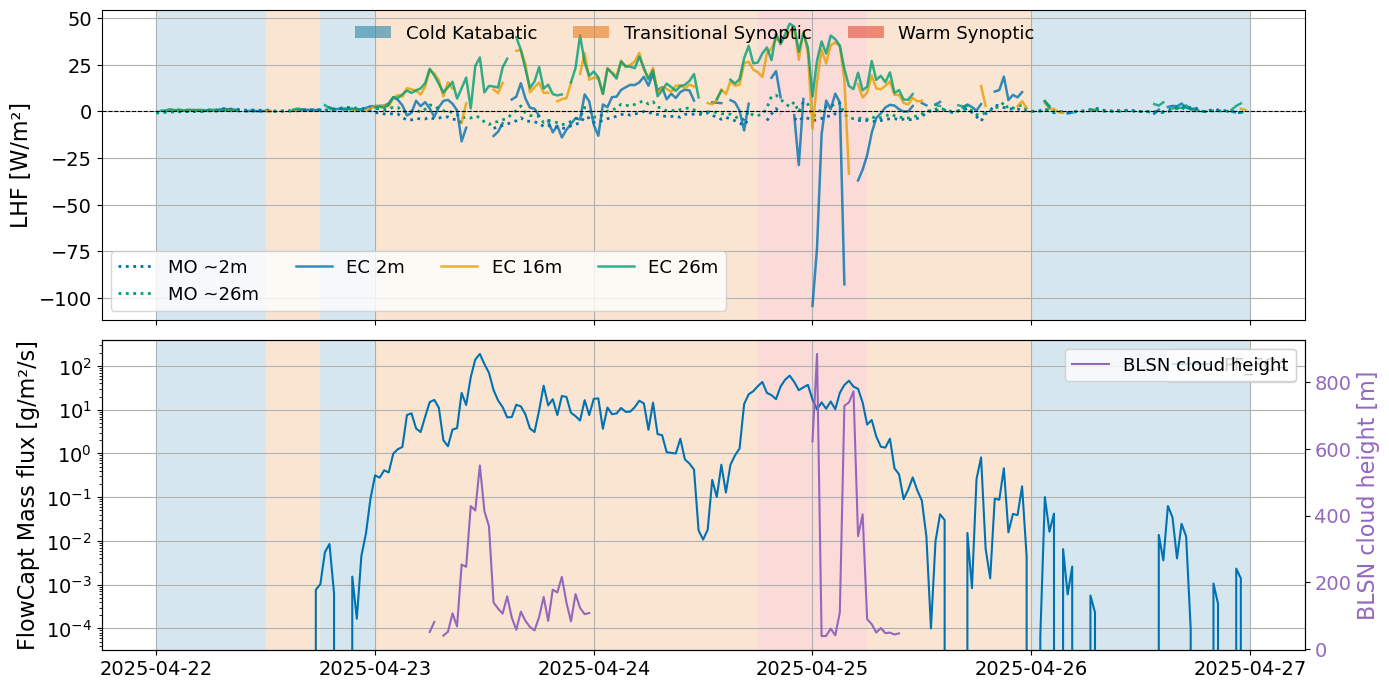

In [46]:
fig, axes = plot_lhf_and_blsn(
    plot_start='2025-04-22', plot_end='2025-04-26',
    result_sfc=result_sfc, result_up=result_up,
    fluxes_sfc=fluxes_sfc, fluxes_low=fluxes_low, fluxes_up=fluxes_up,
    slow_sfc=slow_sfc, blsn_alg=blsn_alg, cluster=cluster,
)
plt.savefig('/home/engbers/Documents/PhD/Meetings/Abstracts_conferences/SCAR/WS_event_LHF_BLSN.png', dpi=400, bbox_inches='tight')

plt.show()

## Plot 2 — LE divergence coloured by sign combination of LE$_{SFC}$ and LE$_{upper}$

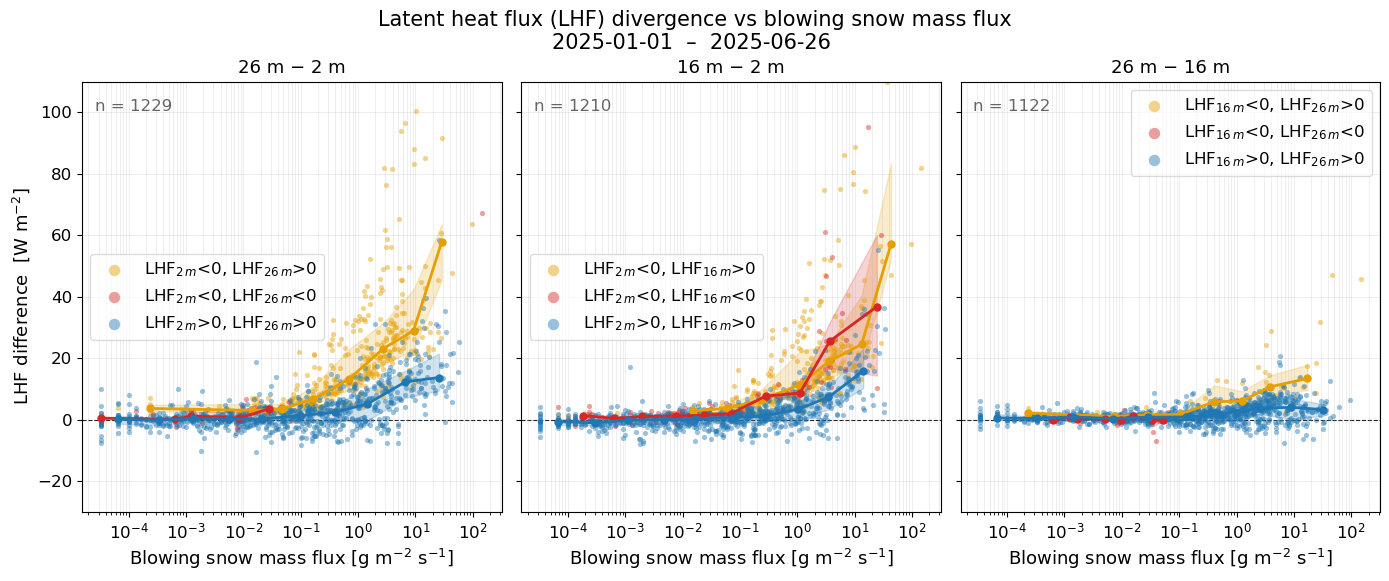

In [47]:
fig, axes = plot_le_divergence_signs(
    fluxes_sfc=fluxes_sfc, fluxes_low=fluxes_low, fluxes_up=fluxes_up,
    slow_sfc=slow_sfc,
    start_scatter='2025-01-01', end_scatter='2025-06-26',
    exclude_start='2025-04-19', exclude_end='2025-04-20',
)
plt.savefig('/home/engbers/Documents/PhD/Meetings/Abstracts_conferences/SCAR/LE_divergence_vs_PF_FC4.png', dpi=500, bbox_inches='tight')
plt.show()

## Plot 2b — same LE divergence figure, panels stacked in a column

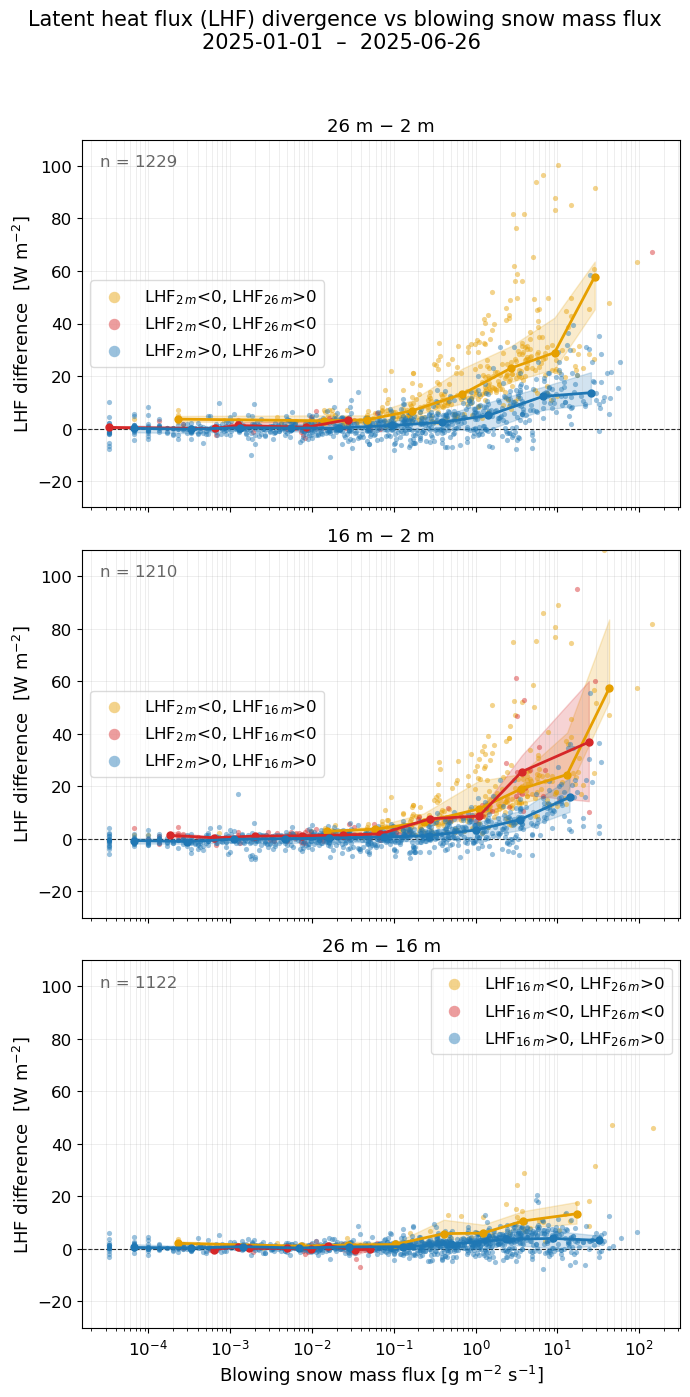

In [48]:
fig, axes = plot_le_divergence_signs(
    fluxes_sfc=fluxes_sfc, fluxes_low=fluxes_low, fluxes_up=fluxes_up,
    slow_sfc=slow_sfc,
    start_scatter='2025-01-01', end_scatter='2025-06-26',
    exclude_start='2025-04-19', exclude_end='2025-04-20',
    layout='column',
)
plt.savefig('/home/engbers/Documents/PhD/Meetings/Abstracts_conferences/SCAR/LE_divergence_vs_PF_FC4_column.png', dpi=500, bbox_inches='tight')
plt.show()

## Plot 3 — SHF divergence vs wind speed, binned by stability

Median sensible-heat-flux difference between levels as a function of wind speed, coloured by SFC stability z/L. Two stacked panels: 16 m − SFC and 26 m − 16 m.

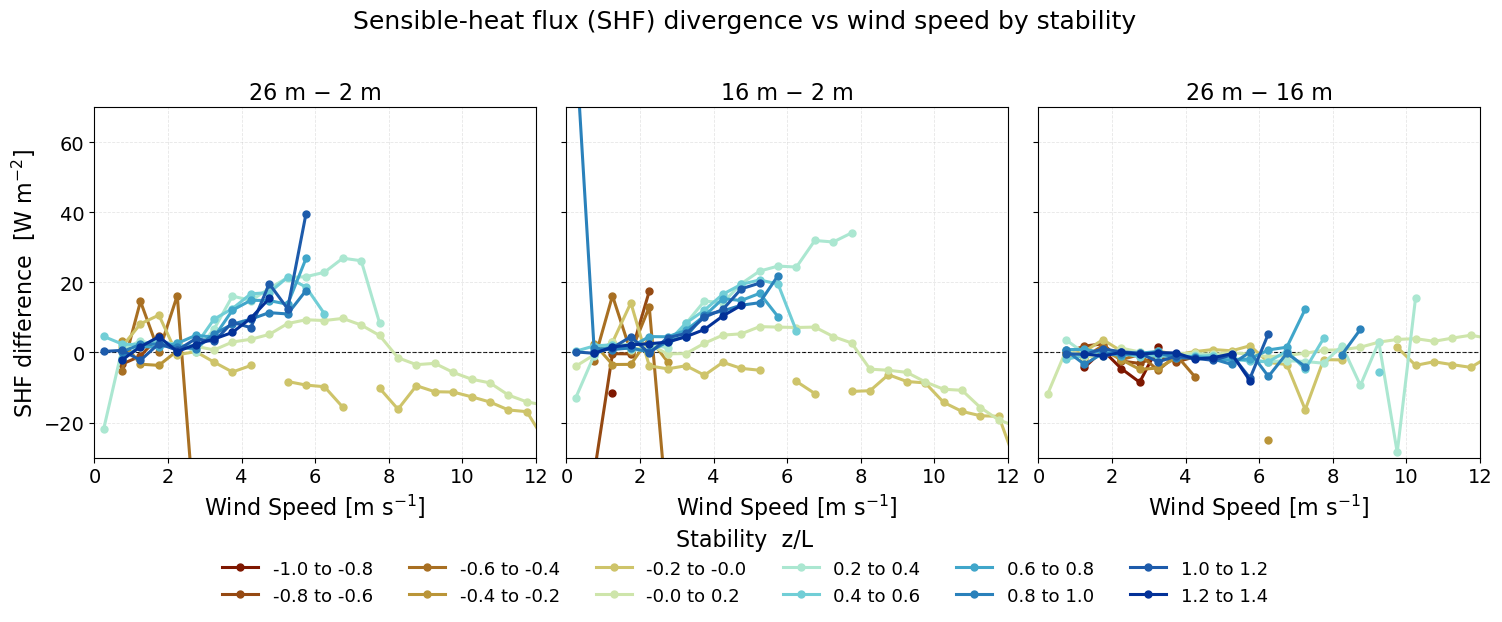

In [49]:
from plotting.func_plots_SCAR import (
    plot_fluxes_and_conditions, plot_le_divergence_signs,
    plot_shf_divergence_wind_stability,
    HEIGHT_COLORS, REGIME_COLORS,
)

fig, axes = plot_shf_divergence_wind_stability(
    fluxes_sfc=fluxes_sfc, fluxes_low=fluxes_low, fluxes_up=fluxes_up,
)
plt.show()

## Plot 3 (2024) — SHF divergence vs wind speed, binned by stability

Same figure for the 2024 season (CSAT3 tower fluxes: SFC / 16 m / 26 m).

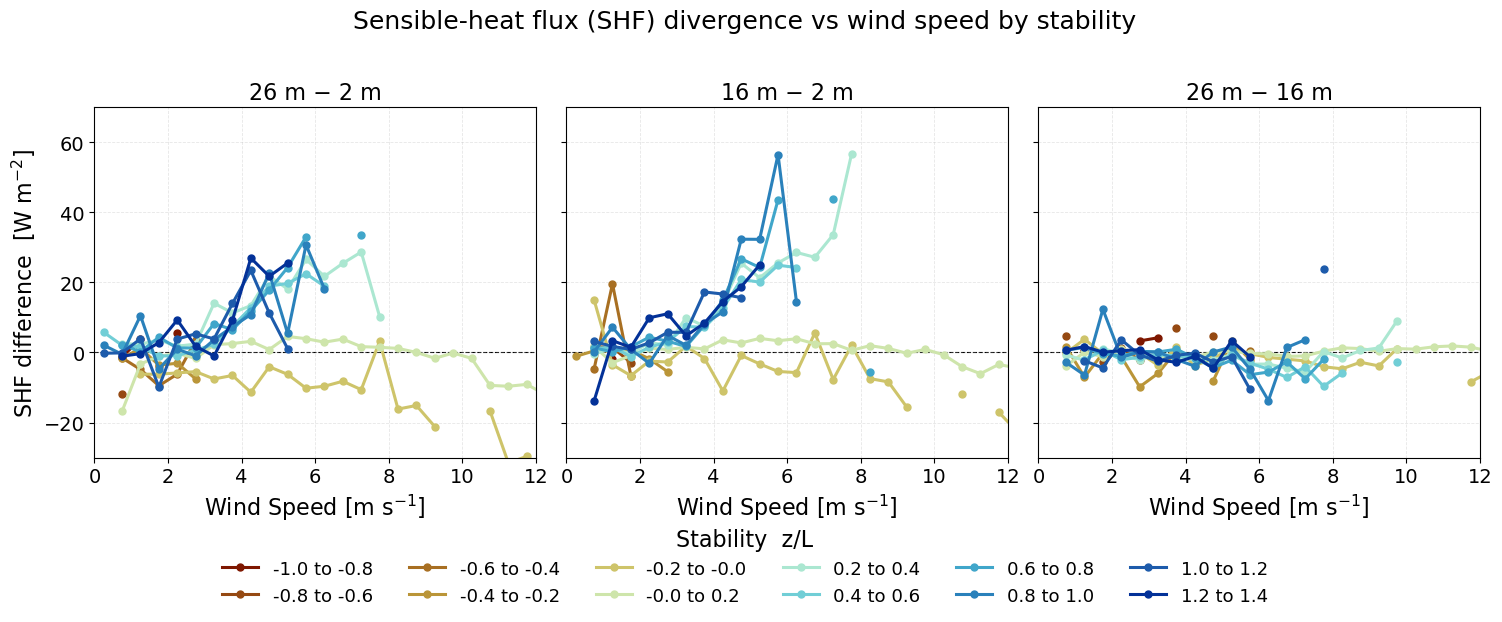

In [50]:
fig, axes = plot_shf_divergence_wind_stability(
    fluxes_sfc=fluxes_sfc_2024, fluxes_low=fluxes_low_2024, fluxes_up=fluxes_up_2024,
)
plt.show()

In [51]:
regimes= pd.read_csv('/home/engbers/Documents/PhD/Data/regimes/regimes_1h_dbs_newthr.csv', index_col=0, parse_dates=True, header=0)
regimes

,dbs_regime
TIMESTAMP,
2024-02-23 05:00:00,Cold Katabatic
2024-02-23 06:00:00,Cold Katabatic
2024-02-23 07:00:00,Cold Katabatic
2024-02-23 08:00:00,Cold Katabatic
2024-02-23 09:00:00,Cold Katabatic
...,...
2025-12-21 09:00:00,Cold Katabatic
2025-12-21 10:00:00,Cold Katabatic
2025-12-21 11:00:00,Cold Katabatic


## Wind roses per regime

One wind-rose per blowing-snow regime (`dbs_regime` from the hourly `regimes` df), using SFC 2 m wind direction/speed, arranged as a column of 3.

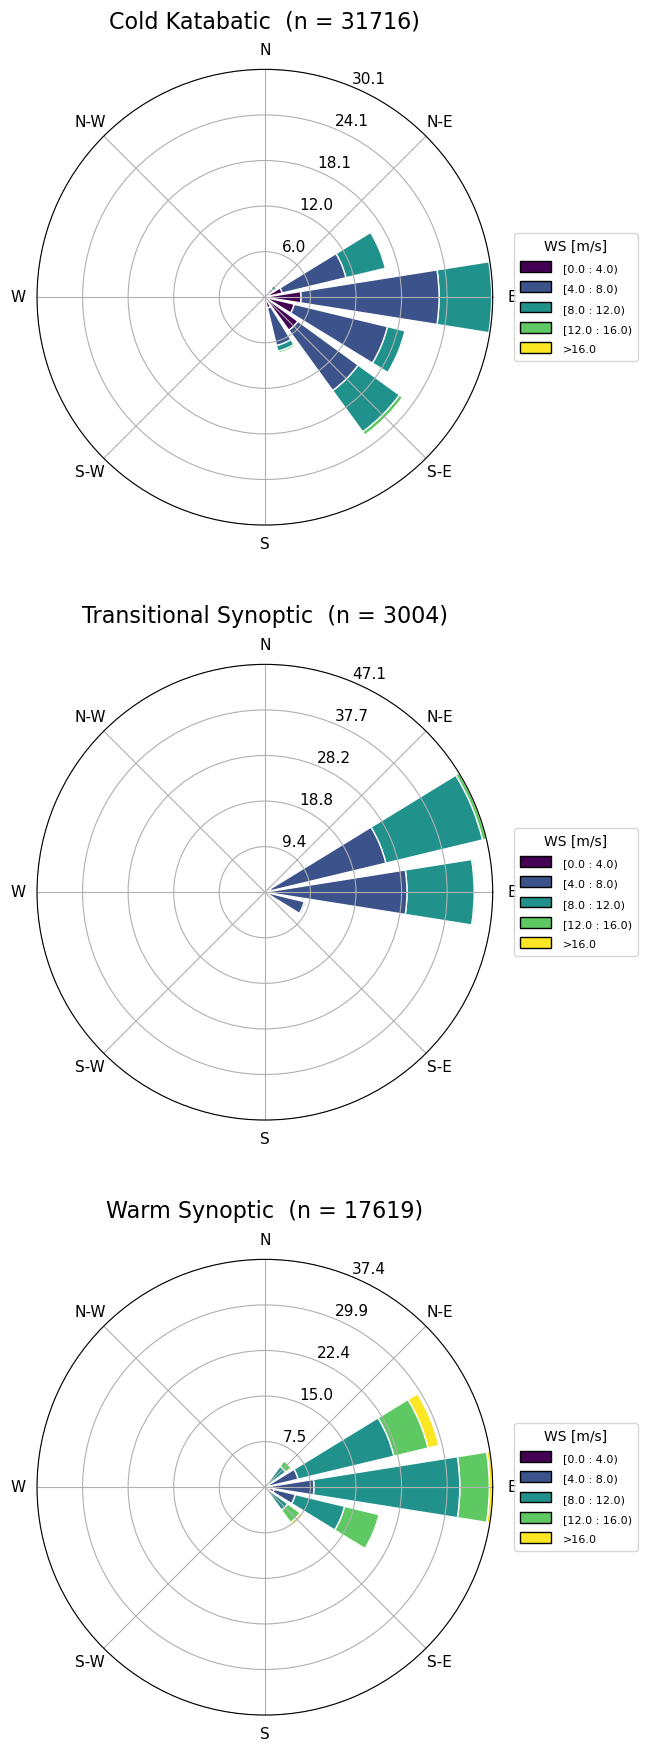

In [52]:
from windrose import WindroseAxes  # registers the 'windrose' projection

# Assign each SFC wind observation to its regime (hourly label, tolerance 1 h),
# then draw one wind-rose per regime as a column of 3.
wd = slow_sfc['WD1']
ws = slow_sfc['WS2_Avg']

reg = regimes['dbs_regime'].reindex(wd.index, method='ffill', tolerance=pd.Timedelta('1h'))
wind = pd.DataFrame({'wd': wd, 'ws': ws, 'regime': reg}).dropna()
wind = wind[wind['ws'] > 0]

# Keep the fixed regime order; only those actually present.
regime_names = [r for r in REGIME_COLORS if r in wind['regime'].unique()]
ws_bins = np.arange(0, 20, 4)

fig = plt.figure(figsize=(6, 18))
for i, regime in enumerate(regime_names):
    sub = wind[wind['regime'] == regime]
    ax = fig.add_subplot(len(regime_names), 1, i + 1, projection='windrose')
    ax.bar(sub['wd'], sub['ws'], normed=True, opening=0.8, edgecolor='white',
           bins=ws_bins, cmap=plt.cm.viridis)
    ax.set_title(f'{regime}  (n = {len(sub)})', fontsize=16, pad=30)
    ax.set_legend(title='WS [m/s]', loc='center left', bbox_to_anchor=(1.05, 0.5), fontsize=11)
    ax.tick_params(labelsize=11)

plt.tight_layout()
plt.show()